# E4: prefix-search cost vs prefix length (track_name, all rows)

Question: how does the cost of `prefix_search` depend on prefix length, and which index is best for F2 (search-as-you-type)?
Data: `E4_prefix_track_name` rows from `results/timings.csv`, one machine, one code version. 500 prefixes per length, 5 replicates.

Every index answers a prefix query as the range `[prefix, prefix + U+10FFFF]` (`indexes/base.py`). So the ordered indexes find the start with a search and walk forward, while the unordered ones (unsorted list, hash table, `ref_dict`) have to look at every key.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv(Path("..") / "results" / "timings.csv")
e4 = df[df["experiment"] == "E4_prefix_track_name"]

# Control the comparison: one machine, one code version.
machine = "ike-mba"
version = e4[e4["machine_id"] == machine]["code_version"].iloc[-1]
e4 = e4[(e4["machine_id"] == machine) & (e4["code_version"] == version)].copy()

e4["prefix_length"] = e4["operation_param"].astype(int)
e4["us_per_op"] = e4["total_ns"] / e4["n_ops"] / 1_000
e4["avg_matches"] = e4["notes"].str.extract(r"avg_matches=([\d.]+)").astype(float)
for c in ["comparisons", "nodes_visited"]:
    e4[c + "_per_op"] = e4[c] / e4["n_ops"]

print(machine, version, len(e4), "rows, n_keys =", e4["n_keys"].iloc[0])
e4.groupby("prefix_length")["avg_matches"].first().rename("avg rows returned per prefix")

ike-mba c2b371c 175 rows, n_keys = 113999


prefix_length
1    5315.5
2     956.0
3     256.9
4     163.9
5      51.4
Name: avg rows returned per prefix, dtype: float64

## Median and IQR across the 5 replicates (µs per prefix query)

In [2]:
summary = (
    e4.groupby(["index_type", "prefix_length"])["us_per_op"]
    .quantile([0.25, 0.5, 0.75]).unstack()
    .rename(columns={0.25: "q25", 0.5: "median", 0.75: "q75"})
)
summary["median"].unstack("prefix_length").round(1)

prefix_length,1,2,3,4,5
index_type,,,,,
avl_tree,1024.2,181.6,49.5,30.0,12.0
bplus_tree,461.9,86.5,25.0,14.7,6.4
hash_table,11481.1,11042.0,10838.9,11140.5,10742.4
ref_bisect,96.6,19.9,7.7,5.5,3.0
ref_dict,2410.5,2276.8,2258.5,2258.5,2259.4
sorted_list,476.1,86.6,24.9,15.8,7.6
unsorted_list,2749.3,2667.1,2669.8,2681.9,2692.7


## Cost vs prefix length

Line = median over replicates, band = IQR. Log y-axis: the indexes are orders of magnitude apart.

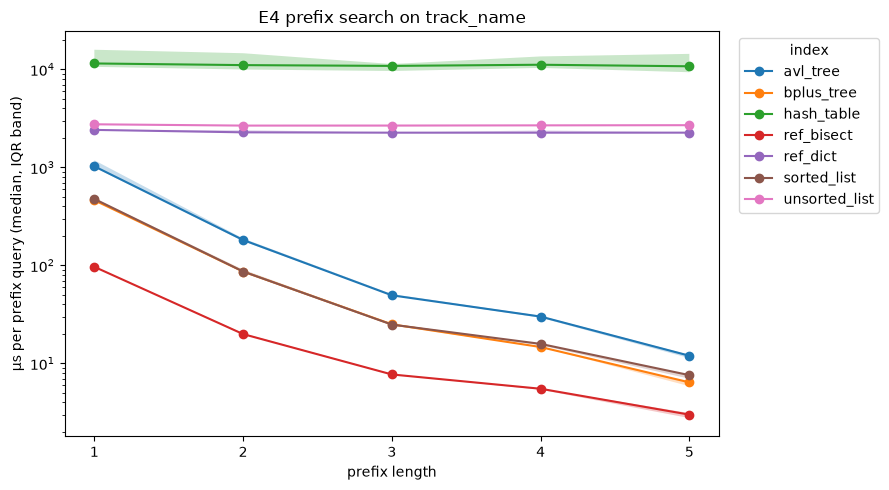

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
for index_type in summary.index.get_level_values(0).unique():
    s = summary.loc[index_type]
    ax.plot(s.index, s["median"], marker="o", label=index_type)
    ax.fill_between(s.index, s["q25"], s["q75"], alpha=0.25)
ax.set(yscale="log", xlabel="prefix length", ylabel="µs per prefix query (median, IQR band)",
       xticks=sorted(e4["prefix_length"].unique()), title="E4 prefix search on track_name")
ax.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

## Separating search cost from output cost

A prefix query costs (find the start) + (walk and copy every match). Short prefixes match thousands of rows, so even a perfect index pays for the output.
Dividing by the average number of rows returned shows how much each index pays *per result*.

In [4]:
per_match = summary["median"].unstack("prefix_length") / e4.groupby("prefix_length")["avg_matches"].first()
per_match.round(3)

prefix_length,1,2,3,4,5
index_type,,,,,
avl_tree,0.193,0.190,0.193,0.183,0.233
bplus_tree,0.087,0.091,0.097,0.090,0.125
hash_table,2.160,11.550,42.191,67.972,208.996
ref_bisect,0.018,0.021,0.030,0.034,0.058
ref_dict,0.453,2.382,8.791,13.780,43.957
sorted_list,0.090,0.091,0.097,0.097,0.148
unsorted_list,0.517,2.790,10.392,16.363,52.388


## Counters per query

Comparisons and nodes visited are deterministic, so one replicate is enough.

In [5]:
counted = e4[e4["comparisons"].notna() & (e4["rep"] == 0)]
counted.pivot_table(index="index_type", columns="prefix_length",
                    values=["comparisons_per_op", "nodes_visited_per_op"]).round(0)

comparisons_per_op                                          \
prefix_length                  1         2         3         4         5   
index_type                                                                 
avl_tree                  3348.0     608.0     173.0     114.0      42.0   
bplus_tree                3350.0     610.0     174.0     115.0      43.0   
hash_table               72396.0   72396.0   72396.0   72396.0   72396.0   
sorted_list               3349.0     609.0     174.0     114.0      43.0   
unsorted_list           113999.0  113999.0  113999.0  113999.0  113999.0   

              nodes_visited_per_op                                          
prefix_length                    1         2         3         4         5  
index_type                                                                  
avl_tree                    3348.0     608.0     173.0     114.0      42.0  
bplus_tree                   158.0      31.0      11.0       9.0       5.0  
hash_table                131072.0  131072.0  131072.0  131072.0  131072.0  
sorted_list                    0.0       0.0       0.0       0.0       0.0  
unsorted_list                  0.0       0.0       0.0       0.0       0.0

## Best index at each prefix length (crossovers)

In [6]:
med = summary["median"].unstack("prefix_length")
main = med.drop(index=["ref_dict", "ref_bisect"])
pd.DataFrame({"best main index": main.idxmin(), "µs": main.min().round(1),
              "runner-up": main.apply(lambda c: c.nsmallest(2).index[-1]),
              "ref_bisect µs": med.loc["ref_bisect"].round(1)})

,best main index,µs,runner-up,ref_bisect µs
prefix_length,,,,
1,bplus_tree,461.9,sorted_list,96.6
2,bplus_tree,86.5,sorted_list,19.9
3,sorted_list,24.9,bplus_tree,7.7
4,bplus_tree,14.7,sorted_list,5.5
5,bplus_tree,6.4,sorted_list,3.0


## Observations (draft: reword in your own words before submitting)

Data: ike-mba, code_version c2b371c (all four bug fixes in), 5 reps.

- **Ordered vs unordered.** The unsorted list, hash table and `ref_dict` cost the same at every prefix length (about 2,700, 11,000 and 2,300 µs), because they examine every key (113,999, 72,396 and 72,396 comparisons per query). That is expected: hashing scatters keys, so nothing tells you where the strings starting with `lov` are. The hash table is about 4× *slower* than the plain unsorted scan, because it also visits all 131,072 buckets per query.
- **Prefix length.** For the ordered indexes, cost drops sharply as the prefix grows (sorted list: 476 µs at length 1 → 7.6 µs at length 5) because the number of matches drops (5,316 → 51 rows on average). Per row returned, the sorted list and B+ tree cost about 0.09–0.15 µs at every length and the AVL tree about 0.19–0.23 µs, so the cost is output-bound: O(log n + k), where k is the number of matches. Comparisons per query ≈ k + log2(n) (3,349 at length 1, 43 at length 5).
- **Sorted list vs `ref_bisect`.** Same algorithm, same answers. `ref_bisect` is 2.5–5× faster, which is the Python-vs-C constant factor. The big-O is identical.
- **B+ tree after the INC-04 fix.** Before the fix, the B+ tree walked every leaf on every query (72,396 comparisons, about 4,000 µs, slower than the unsorted list). After the fix, it makes the same comparisons as the sorted list (3,350 vs 3,349 at length 1) and visits only 5–158 leaves. The B+ tree and the sorted list are now tied: their min–max ranges across the 5 reps overlap at every prefix length (e.g. length 1: 462 [441–498] vs 476 [458–500] µs). The AVL tree is about 2× slower than both, because it follows a pointer per key instead of scanning contiguous leaf arrays.
- **Recommendation for F2: B+ tree.** It ties the sorted list on prefix queries, and E1 (oscar-omen, 584f39d) shows it builds about 3× faster at n = 114,000 (399 vs 1,171 ms). It also inserts in O(log n), while the sorted list shifts O(n) keys per insert, which matters for nightly imports (F4). The trade-off is about 10% more memory (9.2 vs 8.3 MB). If the catalog never changed, the sorted list would be an equally good, simpler choice.